# Histograms: from individual measurements to probabilities

**One dataset. One numerical feature. Several ways to understand its distribution.**

Imagine repeatedly measuring a reference object with a sensor. Our one feature
is **measurement error in millimeters**: measured length minus reference length.
Negative errors mean the sensor reads too low; positive errors mean it reads too high.

We generate 400 independent observations from a normal (Gaussian) model, plot
every value along the x-axis, group those same values into bins, compare bin
widths, and use bin counts to estimate interval probabilities.

This is an original teaching example with new simulated data, explanations,
code, and figures. The supplied histogram chapter was consulted for topic
coverage; its examples, wording, and figures are not reproduced.

**How to use this notebook:** run all cells with a Python 3 Jupyter kernel and
NumPy and Matplotlib installed. All executed outputs are saved. Edit the
controls below and rerun to experiment; no external dataset or PDF is needed.

## 1. Generate one feature from a normal model

The model is

$$X\sim\mathcal N(\mu=0,\ \sigma^2=4),\qquad \sigma=2\text{ mm}.$$

Here the second parameter is the **variance**, in mm$^2$. NumPy's `normal`
function instead takes `scale=2`, the **standard deviation**, in mm.

The observations are a finite sample from this model. Their histogram will
not be a perfectly smooth bell, and their sample mean and standard deviation
will not generally equal the generating parameters exactly. We know the model
here because we chose it; a bell-shaped histogram alone does not prove normality.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Reproducible experiment controls: generate the dataset only here.
SEED = 20261001
n = 400
MODEL_MEAN = 0.0       # millimeters
MODEL_SD = 2.0         # millimeters, not variance

if n < 2 or MODEL_SD <= 0:
    raise ValueError("Use n >= 2 and a strictly positive MODEL_SD.")

rng = np.random.default_rng(SEED)
dataset = rng.normal(loc=MODEL_MEAN, scale=MODEL_SD, size=(n, 1))
feature_name = "measurement_error_mm"
x = dataset[:, 0]     # A view of the one feature, not another dataset.

print(f"Dataset shape: {dataset.shape} -> {n} observations, 1 feature")
print(f"Feature: {feature_name}")
print(f"First 10 values (mm): {np.round(x[:10], 3)}")
print(f"Sample mean: {x.mean():.4f} mm")
print(f"Sample standard deviation: {x.std(ddof=1):.4f} mm")
print(f"Sample range: {x.min():.4f} to {x.max():.4f} mm")

BLUE = "#2563eb"
ORANGE = "#c65a12"
TEAL = "#14806d"
INK = "#0f172a"
MUTED = "#94a3b8"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titleweight": "bold", "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.labelcolor": INK,
})

# Cover EVERY observation. No truncation, clipping, or rejection sampling.
display_limit = max(8.0, 4.0 * np.ceil(np.abs(x).max() / 4.0))

def make_edges(width):
    """Equal-width bins anchored at zero that cover all observations."""
    if not np.isfinite(width) or width <= 0:
        raise ValueError("Bin width must be positive and finite.")
    half_count = int(np.ceil(display_limit / width))
    return np.arange(-half_count, half_count + 1, dtype=float) * width

def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

Dataset shape: (400, 1) -> 400 observations, 1 feature
Feature: measurement_error_mm
First 10 values (mm): [-0.22   1.479 -1.244  0.281  2.493 -0.841  0.571  3.842  3.542 -2.127]
Sample mean: -0.0136 mm
Sample standard deviation: 2.0155 mm
Sample range: -5.6062 to 5.4633 mm


## 2. Plot the individual values along the x-axis

Each dot is one observation, placed at its actual measurement error. Every dot
has the same vertical position: there is **no second feature** on the y-axis.
All observations appear in this plot, but many overlap. The darker center
suggests a concentration of values; it does not tell us exact counts by itself.

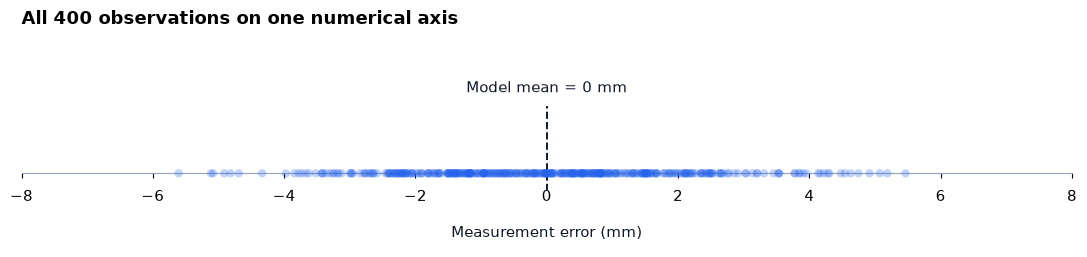

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.7))
ax.scatter(x, np.zeros(n), color=BLUE, alpha=0.28, s=36, edgecolors="none", zorder=3)
ax.vlines(MODEL_MEAN, -0.12, 0.46, color=INK, linestyle="--", linewidth=1.4)
ax.text(MODEL_MEAN, 0.55, f"Model mean = {MODEL_MEAN:g} mm",
        ha="center", color=INK)
ax.set_xlim(-display_limit, display_limit)
ax.set_ylim(-0.50, 0.90)
ax.set_yticks([])
ax.spines[["left", "right", "top"]].set_visible(False)
ax.spines["bottom"].set_position(("data", 0))
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(axis="x", pad=8)
ax.set_xlabel("Measurement error (mm)", labelpad=15)
ax.set_title(f"All {n} observations on one numerical axis", loc="left", pad=12)
fig.tight_layout()
plt.show()

## 3. Turn ranges of values into bins

A histogram divides the numerical axis into intervals and counts the values
inside each interval. For example, the bin $[0,1)$ contains errors that are
**at least 0 mm and less than 1 mm**.

With edges $b_0,b_1,\ldots,b_m$, the count in bin $j$ is

$$c_j=\sum_{i=1}^{n}\mathbf 1\{b_j\le x_i<b_{j+1}\}.$$

The indicator $\mathbf 1\{\cdot\}$ equals 1 when the condition is true and 0
otherwise. Adding the indicators counts the matching observations.

**Boundary convention:** `np.histogram` and Matplotlib use left-inclusive,
right-exclusive bins, except that the final bin includes its right endpoint.
An observation exactly at an interior boundary belongs to the bin on its right.
Our later worked probability intervals end at interior boundaries, so they use
the ordinary $[a,b)$ convention without this final-bin exception.

The x-axis is still measurement error. The y-axis now represents **how many
observations** fall inside each range, not another measured feature.

## 4. Compare bins that are too wide, too narrow, and useful

Use exactly the same observations in all three panels:

| Width in the default experiment | What to inspect |
| :--- | :--- |
| **4 mm: too coarse for this view** | A few broad bars hide the center's shape and the transition into the tails. |
| **0.1 mm: too fine for this sample size** | Many sparse bars make random fluctuations prominent. Small spikes need not represent real clusters. |
| **1 mm: a useful middle choice** | Enough resolution to see the main shape without focusing on every small fluctuation. |

All panels use the same x-axis range. Their count axes are scaled separately
so each shape is visible. Wider bins naturally contain more observations;
compare the overall shapes, not raw bar heights between panels.

There is no universally correct width. A useful choice depends on sample size,
scale, the features you want to see, and the bin boundaries. Choosing a width
solely to force a smooth bell would be misleading.

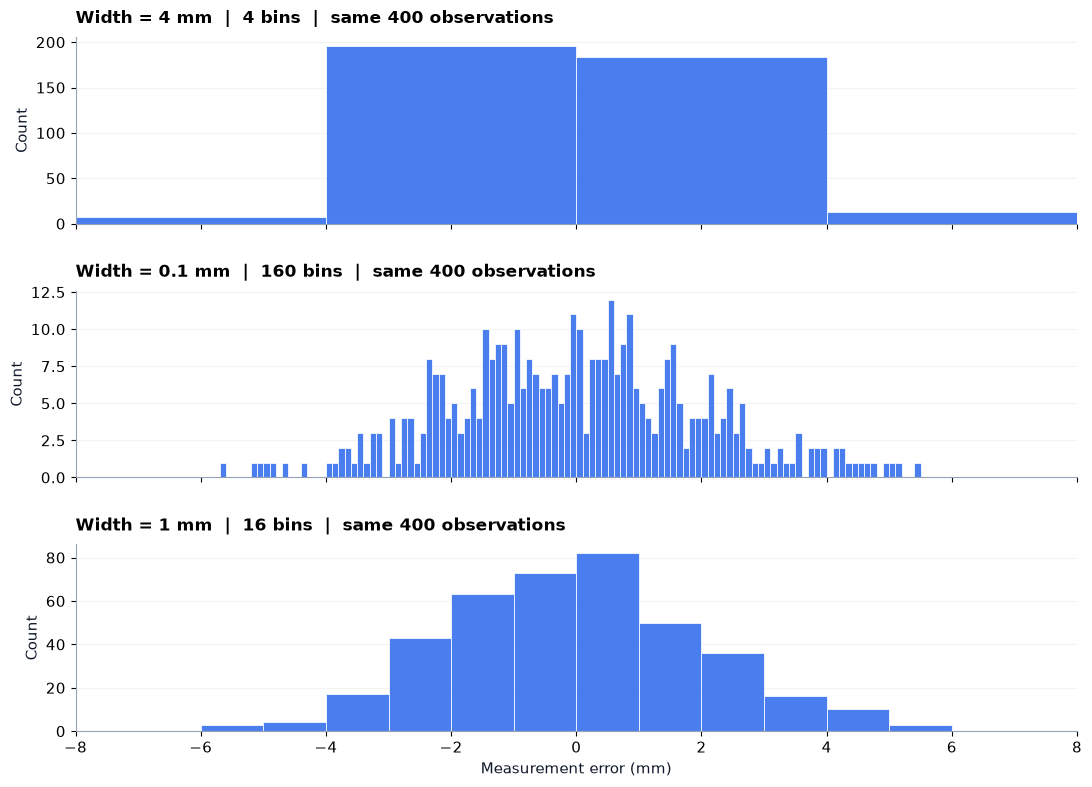

Freedman-Diaconis reference width: 0.736 mm
This is a starting suggestion, not a uniquely correct answer.


In [3]:
# Try changing these widths. The three panels always reuse x.
trial_widths = [4.0, 0.1, 1.0]
trial_edges = [make_edges(width) for width in trial_widths]
trial_limit = max(abs(edges).max() for edges in trial_edges)

fig, axes = plt.subplots(3, 1, figsize=(11, 8.0), sharex=True)
for ax, width, edges in zip(axes, trial_widths, trial_edges):
    trial_counts, _ = np.histogram(x, bins=edges)
    ax.bar(edges[:-1], trial_counts, width=np.diff(edges), align="edge",
           color=BLUE, alpha=0.83, edgecolor="white", linewidth=0.65)
    ax.set_title(f"Width = {width:g} mm  |  {len(trial_counts)} bins  |  same {n} observations",
                 loc="left", fontsize=12, pad=10)
    ax.set_ylabel("Count")
    ax.set_xlim(-trial_limit, trial_limit)
    tidy(ax)
axes[-1].set_xlabel("Measurement error (mm)")
fig.tight_layout(h_pad=2.0)
plt.show()

q25, q75 = np.quantile(x, [0.25, 0.75])
fd_width = 2 * (q75 - q25) / np.cbrt(n)
print(f"Freedman-Diaconis reference width: {fd_width:.3f} mm")
print("This is a starting suggestion, not a uniquely correct answer.")

The printed reference uses the **Freedman-Diaconis rule**:

$$w_{\mathrm{FD}}=\frac{2\,\mathrm{IQR}}{n^{1/3}},\qquad
\mathrm{IQR}=Q_3-Q_1.$$

For the default data it suggests a width near 0.74 mm. We use **1 mm** for the
worked calculations because the interval boundaries are easy to read. We keep
that calculation grid fixed below; the trial widths above are free to change.

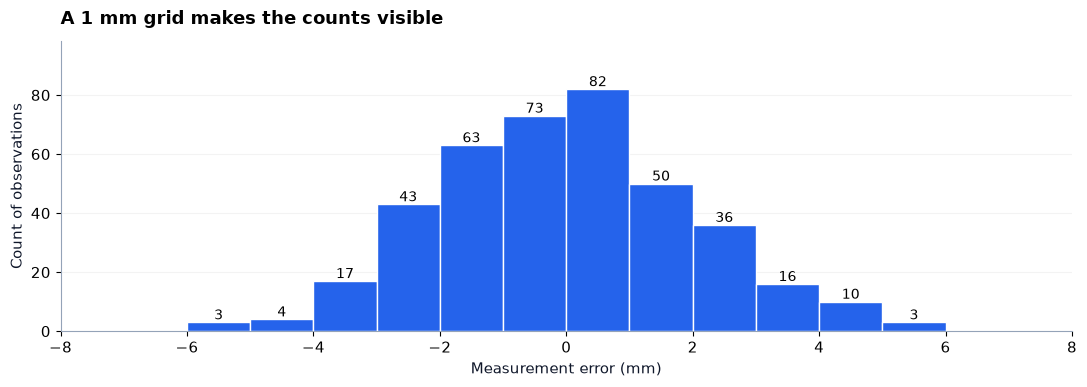

| Bin (mm) | Count | Proportion of all observations |
| :--- | ---: | ---: |
| [-8, -7) | 0 | 0.00% |
| [-7, -6) | 0 | 0.00% |
| [-6, -5) | 3 | 0.75% |
| [-5, -4) | 4 | 1.00% |
| [-4, -3) | 17 | 4.25% |
| [-3, -2) | 43 | 10.75% |
| [-2, -1) | 63 | 15.75% |
| [-1, 0) | 73 | 18.25% |
| [0, 1) | 82 | 20.50% |
| [1, 2) | 50 | 12.50% |
| [2, 3) | 36 | 9.00% |
| [3, 4) | 16 | 4.00% |
| [4, 5) | 10 | 2.50% |
| [5, 6) | 3 | 0.75% |
| [6, 7) | 0 | 0.00% |
| [7, 8] | 0 | 0.00% |
| **Total** | **400** | **100.00%** |

In [4]:
calculation_width = 1.0
edges = make_edges(calculation_width)
counts, _ = np.histogram(x, bins=edges)
bin_widths = np.diff(edges)
proportions = counts / n

fig, ax = plt.subplots(figsize=(11, 4.0))
ax.bar(edges[:-1], counts, width=bin_widths, align="edge",
       color=BLUE, edgecolor="white", linewidth=1)
for left, right, count in zip(edges[:-1], edges[1:], counts):
    if count:
        ax.text((left + right) / 2, count + 1, str(count), ha="center", fontsize=10)
ax.set_ylim(0, max(counts) * 1.20)
ax.set_xlim(edges[0], edges[-1])
ax.set_title("A 1 mm grid makes the counts visible", loc="left", pad=12)
ax.set_xlabel("Measurement error (mm)")
ax.set_ylabel("Count of observations")
tidy(ax)
fig.tight_layout()
plt.show()

rows = ["| Bin (mm) | Count | Proportion of all observations |",
        "| :--- | ---: | ---: |"]
for i, (left, right, count, proportion) in enumerate(zip(edges[:-1], edges[1:], counts, proportions)):
    close_bracket = "]" if i == len(counts) - 1 else ")"
    rows.append(f"| [{left:g}, {right:g}{close_bracket} | {count} | {proportion:.2%} |")
rows.append(f"| **Total** | **{counts.sum()}** | **{proportions.sum():.2%}** |")
display(Markdown("\n".join(rows)))

## 5. Calculate probability estimates from selected bins

For an event $A=[a,b)$ whose endpoints line up with bin edges, add the counts
in the selected bins and divide by the **total number of observations**:

$$
\boxed{\widehat P(a\le X<b)
=\frac{\sum_{j:\,[b_j,b_{j+1})\subseteq[a,b)}c_j}{n}
=\frac{\#\{i:a\le x_i<b\}}{n}}.
$$

We will calculate three different events:

1. **One bin:** $0\le X<1$ mm, a small positive error.
2. **Several adjacent bins:** $-2\le X<2$ mm, an error close to zero.
3. **A tail interval:** $4\le X<6$ mm, a relatively large positive error.

The denominator stays $n$ in each calculation. Dividing by the number of
selected bins or the number of observations inside the selected range would
answer a different question.

| Event | Selected bin counts | Total in event | Estimated probability |
| :--- | :--- | ---: | ---: |
| 0 ≤ X < 1 mm | 82 | 82 | 82/400 = 20.50% |
| -2 ≤ X < 2 mm | 63 + 73 + 82 + 50 | 268 | 268/400 = 67.00% |
| 4 ≤ X < 6 mm | 10 + 3 | 13 | 13/400 = 3.25% |

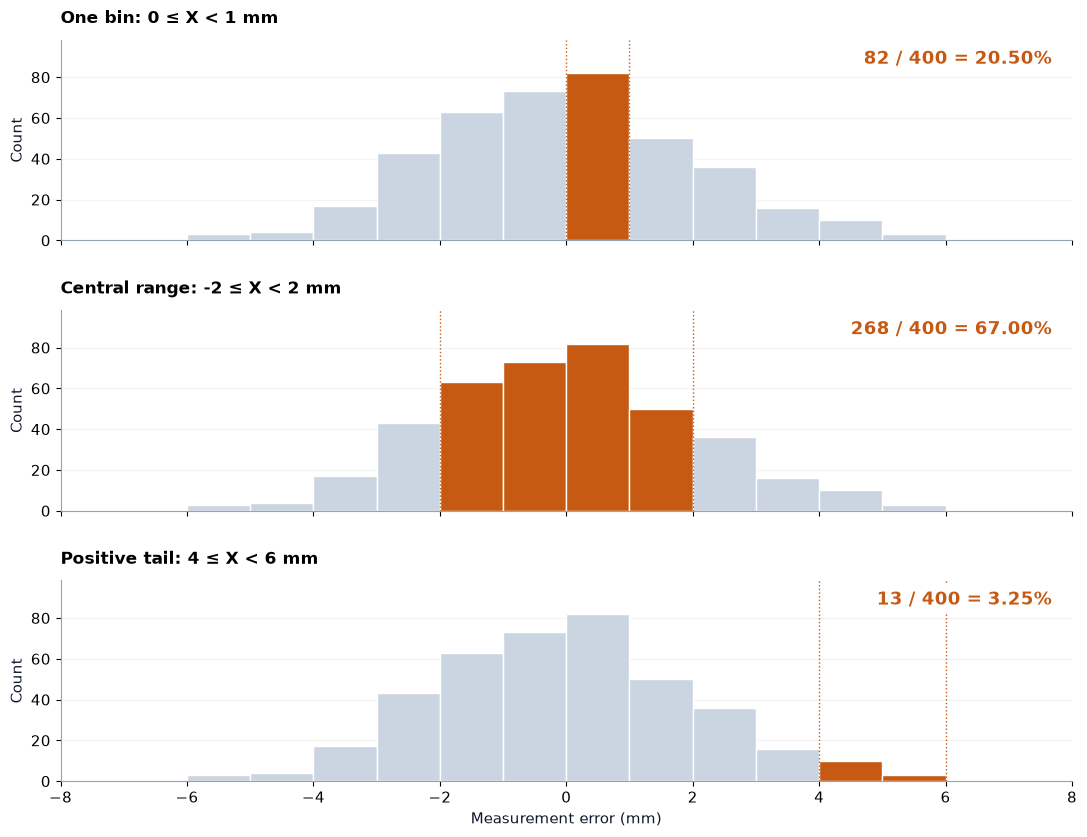

In [5]:
events = [
    {"label": "One bin", "a": 0.0, "b": 1.0},
    {"label": "Central range", "a": -2.0, "b": 2.0},
    {"label": "Positive tail", "a": 4.0, "b": 6.0},
]

event_results = []
rows = ["| Event | Selected bin counts | Total in event | Estimated probability |",
        "| :--- | :--- | ---: | ---: |"]
for event in events:
    a, b = event["a"], event["b"]
    if not (a < b and np.any(np.isclose(edges, a)) and np.any(np.isclose(edges, b))):
        raise ValueError("Use ordered interval endpoints that match the counting-grid edges.")
    selected = (edges[:-1] >= a) & (edges[1:] <= b)
    selected_counts = counts[selected]
    event_count = int(selected_counts.sum())
    raw_count = int(np.count_nonzero((x >= a) & (x < b)))
    if event_count != raw_count:
        raise ValueError("The probability interval must align with this histogram's bin edges.")
    probability = event_count / n
    result = {**event, "mask": selected, "count": event_count,
              "probability": probability, "raw_count": raw_count}
    event_results.append(result)
    addition = " + ".join(str(value) for value in selected_counts)
    rows.append(f"| {a:g} ≤ X < {b:g} mm | {addition} | {event_count} | {event_count}/{n} = {probability:.2%} |")
display(Markdown("\n".join(rows)))

fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, result in zip(axes, event_results):
    a, b = result["a"], result["b"]
    colors = [ORANGE if selected else "#cbd5e1" for selected in result["mask"]]
    ax.bar(edges[:-1], counts, width=bin_widths, align="edge",
           color=colors, edgecolor="white", linewidth=1)
    ax.axvline(a, color=ORANGE, linestyle=":", linewidth=1)
    ax.axvline(b, color=ORANGE, linestyle=":", linewidth=1)
    ax.set_title(f"{result['label']}: {a:g} ≤ X < {b:g} mm", loc="left", fontsize=12, pad=12)
    ax.text(0.98, 0.88, f"{result['count']} / {n} = {result['probability']:.2%}",
            transform=ax.transAxes, ha="right", color=ORANGE,
            fontsize=13, fontweight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.96, "pad": 4})
    ax.set_ylabel("Count")
    ax.set_ylim(0, max(counts) * 1.20)
    ax.set_xlim(edges[0], edges[-1])
    tidy(ax)
axes[-1].set_xlabel("Measurement error (mm)")
fig.tight_layout(h_pad=2.0)
plt.show()

In [6]:
central_result = event_results[1]
p_central = central_result["probability"]
display(Markdown(
    f"**Meaning of the central interval:** {central_result['count']} of the {n} "
    f"recorded errors lie between -2 mm (included) and +2 mm (excluded). "
    f"The observed proportion is **{p_central:.2%}**.\n\n"
    f"If you pick one row uniformly at random from this recorded dataset, "
    f"the probability it meets that condition is exactly {p_central:.2%}. "
    f"For a **new measurement from the same stable process**, {p_central:.2%} "
    "is an estimate based on this sample, not a certainty or a guarantee "
    "about the next measurement."
))

**Meaning of the central interval:** 268 of the 400 recorded errors lie between -2 mm (included) and +2 mm (excluded). The observed proportion is **67.00%**.

If you pick one row uniformly at random from this recorded dataset, the probability it meets that condition is exactly 67.00%. For a **new measurement from the same stable process**, 67.00% is an estimate based on this sample, not a certainty or a guarantee about the next measurement.

## 6. Compare the histogram estimate with the known normal model

The histogram uses observed counts. The model uses the normal distribution:

$$P(a\le X<b)=F(b)-F(a),$$

where $F$ is the normal cumulative distribution function. In this simulation,
the generating parameters are known, so this gives an exact **model-based**
probability up to numerical precision. In a real dataset, assuming a normal
model or estimating its parameters adds uncertainty.

For a normal distribution, the interval from $\mu-\sigma$ to $\mu+\sigma$
contains approximately 68.27% of the probability. A finite sample does not have
to place exactly 68.27% of its observations there.

In [7]:
def normal_cdf(value):
    z = (float(value) - MODEL_MEAN) / (MODEL_SD * math.sqrt(2))
    return 0.5 * (1 + math.erf(z))

def model_probability(a, b):
    return normal_cdf(b) - normal_cdf(a)

rows = ["| Interval (mm) | Histogram estimate | Known normal-model probability |",
        "| :--- | ---: | ---: |"]
for result in event_results:
    a, b = result["a"], result["b"]
    rows.append(f"| [{a:g}, {b:g}) | {result['probability']:.2%} | {model_probability(a,b):.2%} |")
display(Markdown("\n".join(rows)))

| Interval (mm) | Histogram estimate | Known normal-model probability |
| :--- | ---: | ---: |
| [0, 1) | 20.50% | 19.15% |
| [-2, 2) | 67.00% | 68.27% |
| [4, 6) | 3.25% | 2.14% |

## 7. Counts, proportions, and density are different vertical scales

| Histogram scale | Height of bin $j$ | How to obtain the interval probability |
| :--- | :--- | :--- |
| **Count** | $c_j$ | Add selected counts and divide by $n$. |
| **Proportion** | $c_j/n$ | Add selected heights when the event is a union of complete bins. |
| **Density** | $h_j=c_j/(n w_j)$, where $w_j$ is bin width | Add selected **areas**: height $\times$ width. |

For a density histogram,

$$h_jw_j=\frac{c_j}{n},\qquad \sum_j h_jw_j=1.$$

Its vertical unit is **per millimeter**. A density height alone is not a
probability; a probability is dimensionless. Density heights can exceed 1
for concentrated distributions without violating probability rules.

Below, use **2 mm bins** so that the distinction between height and area is
visible numerically. The data are unchanged. The smooth curve is the known
normal density, while the bars are calculated from the sample.

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}
\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].$$

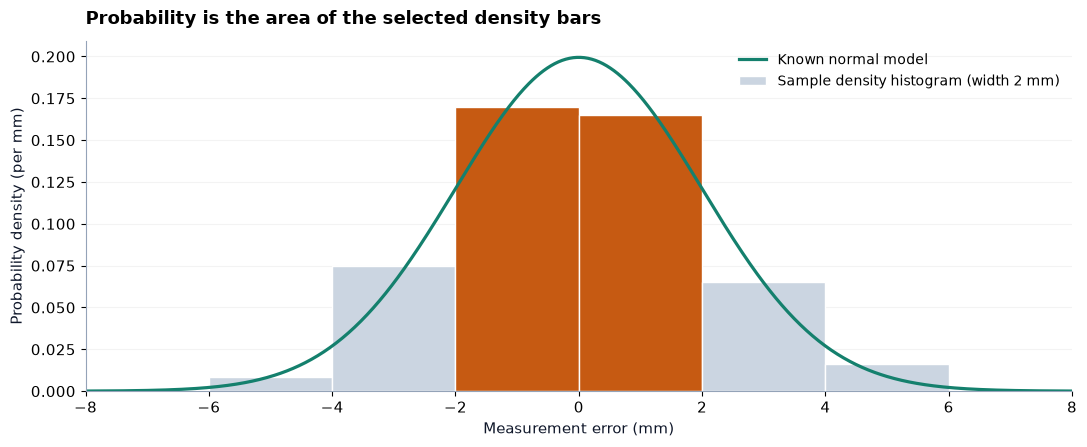

| Selected bin (mm) | Count | Density height (per mm) | Width (mm) | Area = proportion |
| :--- | ---: | ---: | ---: | ---: |
| [-2, 0) | 136 | 0.1700 | 2 | 0.3400 |
| [0, 2) | 132 | 0.1650 | 2 | 0.3300 |

Selected histogram area: 0.6700 = 67.00%
The same event counted directly: 0.6700
Total histogram area: 1.0000
Known model area between -2 and +2 mm: 0.6827


In [8]:
density_edges = make_edges(2.0)
density_counts, _ = np.histogram(x, bins=density_edges)
density_widths = np.diff(density_edges)
density_heights = density_counts / (n * density_widths)
density_selected = (density_edges[:-1] >= -2) & (density_edges[1:] <= 2)
density_event_area = float(np.sum(density_heights[density_selected] * density_widths[density_selected]))
density_total_area = float(np.sum(density_heights * density_widths))

grid = np.linspace(density_edges[0], density_edges[-1], 800)
normal_pdf = np.exp(-0.5 * ((grid - MODEL_MEAN) / MODEL_SD)**2) / (MODEL_SD * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(11, 4.6))
colors = [ORANGE if selected else "#cbd5e1" for selected in density_selected]
ax.bar(density_edges[:-1], density_heights, width=density_widths,
       align="edge", color=colors, edgecolor="white", linewidth=1,
       label="Sample density histogram (width 2 mm)")
ax.plot(grid, normal_pdf, color=TEAL, linewidth=2.3, label="Known normal model")
ax.set_title("Probability is the area of the selected density bars", loc="left", pad=12)
ax.set_xlabel("Measurement error (mm)")
ax.set_ylabel("Probability density (per mm)")
ax.set_xlim(density_edges[0], density_edges[-1])
ax.legend(frameon=False, loc="upper right", fontsize=10)
tidy(ax)
fig.tight_layout()
plt.show()

rows = ["| Selected bin (mm) | Count | Density height (per mm) | Width (mm) | Area = proportion |",
        "| :--- | ---: | ---: | ---: | ---: |"]
for j in np.flatnonzero(density_selected):
    rows.append(f"| [{density_edges[j]:g}, {density_edges[j+1]:g}) | {density_counts[j]} "
                f"| {density_heights[j]:.4f} | {density_widths[j]:g} "
                f"| {density_heights[j] * density_widths[j]:.4f} |")
display(Markdown("\n".join(rows)))
print(f"Selected histogram area: {density_event_area:.4f} = {density_event_area:.2%}")
print(f"The same event counted directly: {p_central:.4f}")
print(f"Total histogram area: {density_total_area:.4f}")
print(f"Known model area between -2 and +2 mm: {model_probability(-2, 2):.4f}")

## 8. When the question cuts through a bin

Suppose we want $P(0.3\le X<1.6)$. The endpoints cut through the 1 mm bins
$[0,1)$ and $[1,2)$. The stored bin counts do not tell us exactly where the
observations lie inside those bins.

- **If the raw data are available:** count observations satisfying the condition.
  This gives the exact observed proportion for the sample.
- **If only the histogram is available:** one possible approximation is to
  assume values are uniformly distributed within each bin and take the
  corresponding fraction of each bin's probability mass.

For that piecewise-uniform approximation,

$$\widehat P_{\mathrm{hist}}(a\le X<b)
=\sum_j \frac{c_j}{n}\,
\frac{\max\{0,\min(b,b_{j+1})-\max(a,b_j)\}}{b_{j+1}-b_j}.$$

For this interval, the approximation includes 70% of the $[0,1)$ bin and 60%
of the $[1,2)$ bin. Those percentages refer to bin widths, not known locations
of the observations.

In [9]:
partial_a, partial_b = 0.3, 1.6
raw_partial_count = int(np.count_nonzero((x >= partial_a) & (x < partial_b)))
raw_partial_probability = raw_partial_count / n
overlap_widths = np.maximum(0.0, np.minimum(edges[1:], partial_b) - np.maximum(edges[:-1], partial_a))
partial_hist_probability = float(np.sum(proportions * overlap_widths / bin_widths))

display(Markdown(
    "| Calculation for [0.3, 1.6) mm | Result |\n"
    "| :--- | ---: |\n"
    f"| Exact sample proportion from raw data | {raw_partial_count}/{n} = {raw_partial_probability:.2%} |\n"
    f"| Approximation using fractions of histogram bins | {partial_hist_probability:.2%} |\n"
    f"| Known normal-model probability | {model_probability(partial_a, partial_b):.2%} |"
))
print("These quantities can differ. The histogram approximation assumes uniformity inside each bin.")

| Calculation for [0.3, 1.6) mm | Result |
| :--- | ---: |
| Exact sample proportion from raw data | 96/400 = 24.00% |
| Approximation using fractions of histogram bins | 21.85% |
| Known normal-model probability | 22.85% |

These quantities can differ. The histogram approximation assumes uniformity inside each bin.


## 9. Empty bins and the limits of the observed range

An empty sample bin has observed proportion zero. This does **not** prove that
a future observation cannot fall in that interval. In the default dataset,
the bin $[7,8)$ mm is empty, but the generating normal model assigns it positive
probability.

Similarly, our histogram covers all recorded observations, so the total
observed proportion within its range is 1. A normal distribution has tails
extending beyond any finite range, so a future observation can lie outside it.

More representative observations help estimate the distribution. Narrowing
bins by itself does not create more information, and observed data cannot
make the normal distribution's mathematical tails disappear.

In [10]:
empty_a, empty_b = 7.0, 8.0
empty_count = int(np.count_nonzero((x >= empty_a) & (x < empty_b)))
empty_probability = empty_count / n
empty_model_probability = model_probability(empty_a, empty_b)
outside_model_probability = normal_cdf(edges[0]) + (1 - normal_cdf(edges[-1]))

display(Markdown(
    f"For **[7, 8) mm**, the sample contains **{empty_count}/{n}** observations "
    f"(**{empty_probability:.4%}**), while the known normal-model probability "
    f"is **{empty_model_probability:.4%}**.\n\n"
    f"All recorded observations lie within the histogram range "
    f"**[{edges[0]:g}, {edges[-1]:g}] mm**. The normal model still assigns "
    f"**{outside_model_probability:.4%}** probability outside that range."
))

For **[7, 8) mm**, the sample contains **0/400** observations (**0.0000%**), while the known normal-model probability is **0.0201%**.

All recorded observations lie within the histogram range **[-8, 8] mm**. The normal model still assigns **0.0063%** probability outside that range.

## 10. Experiment and interpret

1. **Change only the bin widths** in `trial_widths`. Try `[8.0, 0.05, 0.75]`.
   Rerun from the width-comparison cell. The observations and raw-data interval
   proportions stay the same; the display changes.
2. **Change the sample size** from 400 to 80, then to 2,000, and run all cells.
   Compare the roughness of the 0.1 mm histogram and the probability estimates.
   These are alternative runs, each using one dataset and one feature.
3. **Change `SEED`** and run all cells. The generating distribution is unchanged,
   but the sample and its estimated probabilities change.
4. **Change `MODEL_SD`** from 2 to 1 or 3. Predict whether the fixed interval
   $[-2,2)$ will contain more or less probability. Run all cells and compare
   the sample estimate with the updated model calculation.

The probability examples use a fixed 1 mm counting grid to keep their selected
intervals aligned with bin boundaries. Changing `trial_widths` affects only
the comparison plots. Written examples describe the default settings; the
code outputs update when the controls change.

**What to remember:** a histogram groups one numerical feature into intervals.
For whole bins, probability estimates come from selected counts divided by
the total count. For a density histogram, use selected area. Bin width changes
how much detail you see; it does not change the recorded values or make a
sample probability equal to the population/model probability.